# PheroSAM-3D — Week 7 baseline experiment (Course Phase 1)

This notebook produces the **initial implementation, baseline model and initial experimental results** for Phase 1 (deliverables 8–10).

**What it does, end to end**

1. Downloads the multi-site prostate T2 MRI collection (6 hospitals) and checks that it loads.
2. Trains a small **2D U-Net proposer** on one hospital only (RUNMC) — the other hospitals are unseen test domains.
3. Runs **MedSAM (frozen)** once per slice and caches the image embeddings.
4. Builds **3–5 candidate boxes per slice + a "no object" option** from the proposer, and decodes each with MedSAM.
5. Compares, on the same test volumes:
   - Proposer alone · MedSAM best box per slice · MedSAM greedy propagation *(baselines)*
   - Random search · DP (Viterbi) *(comparison optimizers)*
   - **MMAS ant colony** and **MMAS + DP seed** *(the NIC method, first version)*
   - Oracle selection · Oracle boxes *(upper bounds, use the ground truth)*
6. Reports 3D Dice, HD95, slice consistency, a Wilcoxon test, figures, and early go/no-go checks.

**Scope of this first version (say this in the report):** the fitness uses only the *local* terms (MedSAM confidence + slice-to-slice smoothness). DP is exact for those, so MMAS is expected to *match* DP here, not beat it. The global terms (3D shape, penalties), ACO_R box refinement, flags/corrections and competing colonies come in Phase 2. Section 9 gives a first demo of why the colony matters once a global term is added.

**How to run:** Colab → *Runtime → Change runtime type → T4 GPU* → *Run all*. About 15–25 minutes. Everything is written to `pherosam/outputs/` (CSVs + PNG figures), and the last cell zips it for download. On Kaggle, turn on GPU and Internet.

## 0 · Setup

In [14]:
!nvidia-smi -L || echo "No GPU found: switch the runtime to GPU (Colab: Runtime > Change runtime type > T4 GPU)."
%pip install -q nibabel gdown scikit-image "git+https://github.com/facebookresearch/segment-anything.git"

GPU 0: Tesla T4 (UUID: GPU-bd192bec-0c29-69cd-9ed7-fee99021fbe8)
GPU 1: Tesla T4 (UUID: GPU-2bd362d8-6c0b-19b4-afef-89ebf4b1bfbb)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


In [15]:
# ===================== CONFIG — edit here =====================
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/working")
WORK = Path("/content/pherosam" if IN_COLAB else "/kaggle/working/pherosam" if IN_KAGGLE else "./pherosam")
DATA_ROOT = WORK / "data"              # the multi-site prostate data is unzipped here
CKPT_PATH = WORK / "medsam_vit_b.pth"  # MedSAM checkpoint
OUT = WORK / "outputs"

# Download sources (official links from the dataset page and the MedSAM repo)
PROSTATE_GDRIVE_ID = "1TtrjnlnJ1yqr5m4LUGMelKTQXtvZaru-"   # liuquande.github.io/SAML  (Processed_data_nii)
MEDSAM_GDRIVE_FILE_ID = "1UAmWL88roYR7wKlnApw5Bcuzf2iQgk6_" # medsam_vit_b.pth only, inside the official MedSAM Drive folder
# Fallback only if Google Drive refuses (community copy on Hugging Face, not official; the sanity check below verifies it)
MEDSAM_MIRROR_URL = "https://huggingface.co/spaces/dennistrujillo/MedSAMTest/resolve/main/medsam_vit_b.pth"

# Domains: train the proposer on one site, test on others
SOURCE_SITE = "RUNMC"
TEST_SITES = ["BMC", "BIDMC", "HK"]    # any of: BMC, I2CVB, UCL, BIDMC, HK
N_TEST_PER_SITE = 4                    # 4 x 3 sites = 12 test volumes; use None for all
SEEDS = [0, 1, 2]                      # seeds for the stochastic methods

# Proposer (small 2D U-Net)
UNET_SIZE, UNET_BASE = 256, 32
UNET_EPOCHS, UNET_BATCH, UNET_LR = 40, 16, 1e-3

# Candidate boxes per slice
THRESHOLDS = [0.5, 0.3, 0.7]   # probability thresholds
MARGINS = [0, 6]               # box margin in pixels
K_MAX = 5                      # max object candidates per slice (+1 "no object")
MIN_AREA = 30                  # ignore components / masks smaller than this (pixels)
WINDOW_THR, WINDOW_EXTEND = 0.3, 2   # slices searched = where proposer max prob > thr, +/- extend
CONF_SOURCE = "iou_pred"       # MedSAM confidence: "iou_pred" or "stability"

# Label-free fitness  F = W_CONF*Conf + W_SMOOTH*Smooth - W_PEN*Pen
W_CONF, W_SMOOTH, W_PEN = 1.0, 1.0, 0.0   # W_PEN = 0: local terms only (Phase 1)

# MMAS (budget = N_ANTS * N_ROUNDS fitness evaluations; random search gets the same)
N_ANTS, N_ROUNDS = 20, 30
ALPHA, BETA, GAMMA = 1.0, 2.0, 1.0     # pheromone, MedSAM confidence, smoothness weights
RHO, P_BEST = 0.1, 0.05                # evaporation, MMAS p_best for tau_min
GB_SWITCH, PATIENCE = 10, 10           # iteration-best -> global-best after N rounds; early stop
KAPPA_EPS, TAU_SEED_FRAC = 0.05, 0.5   # smoothing for zero overlap; DP-seed level for non-DP edges
KAPPA_EMPTY = 0.5                      # neutral smoothness for any transition involving "no object"

GREEDY_MARGIN = 5                      # box margin when propagating a mask to the next slice
N_RANDOM_PATHS_CHECK = 200             # random paths per volume for the fitness-vs-Dice check

In [16]:
import time, json, math, random, glob, zipfile, shutil, warnings
import numpy as np
import pandas as pd
import nibabel as nib
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import ndimage, stats
from skimage import transform as sk_transform

warnings.filterwarnings("ignore", category=UserWarning)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| torch", torch.__version__)
for p in (WORK, DATA_ROOT, OUT, OUT / "figures"):
    p.mkdir(parents=True, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
set_seed(0)

# Figure style: light surface, recessive axes, one accent colour for the NIC method
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3de", "#fcfcfb"
C_NIC, C_NIC2, C_BASE, C_BOUND = "#2a78d6", "#6250d6", "#8f8e88", "#c3c2b7"
C_ORANGE = "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})
def savefig(fig, name):
    fig.savefig(OUT / "figures" / f"{name}.png"); plt.show()

Device: cuda | torch 2.11.0+cu128


## 1 · Data: multi-site prostate MRI

Six hospitals from three public collections (NCI-ISBI 2013, I2CVB, PROMISE12), already converted to NIfTI and resized to 384×384 in-plane by the dataset authors. Masks are binarised (any label > 0 is prostate). The slice axis is detected automatically.

If the automatic download fails (Google Drive quota), download `Processed_data_nii` from the dataset page in your browser and add it to the notebook as a Kaggle dataset (*Add Input → Upload*). The loader searches for the six site folders below `DATA_ROOT` and below `/kaggle/input`.

In [17]:
KNOWN_SITES = ["RUNMC", "BMC", "I2CVB", "UCL", "BIDMC", "HK"]

def find_site_dirs(root):
    found = {}
    for p in sorted(Path(root).rglob("*")):
        if p.is_dir() and p.name.upper() in KNOWN_SITES and p.name.upper() not in found:
            if any(p.glob("*.nii*")):
                found[p.name.upper()] = p
    return found

site_dirs = find_site_dirs(DATA_ROOT)
if len(site_dirs) < 2 and Path("/kaggle/input").exists():      # data added as a Kaggle dataset
    site_dirs = find_site_dirs("/kaggle/input")
if len(site_dirs) < 2:
    import gdown
    zip_path = WORK / "prostate_multisite.zip"
    if not zip_path.exists():
        print("Downloading the multi-site prostate data ...")
        gdown.download(id=PROSTATE_GDRIVE_ID, output=str(zip_path), quiet=False)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_ROOT)
    site_dirs = find_site_dirs(DATA_ROOT)

assert SOURCE_SITE in site_dirs, f"Source site {SOURCE_SITE} not found under {DATA_ROOT}; found {list(site_dirs)}"
print({k: str(v) for k, v in site_dirs.items()})

{'BIDMC': '/kaggle/working/pherosam/data/BIDMC', 'BMC': '/kaggle/working/pherosam/data/BMC', 'HK': '/kaggle/working/pherosam/data/HK', 'I2CVB': '/kaggle/working/pherosam/data/I2CVB', 'RUNMC': '/kaggle/working/pherosam/data/RUNMC', 'UCL': '/kaggle/working/pherosam/data/UCL'}


In [18]:
def strip_ext(name):
    return name[:-7] if name.endswith(".nii.gz") else name[:-4] if name.endswith(".nii") else name

def list_cases(site, folder):
    files = sorted(Path(folder).glob("*.nii*"))
    segs = {strip_ext(f.name).lower().replace("_segmentation", "").replace("_seg", ""): f
            for f in files if "seg" in f.name.lower()}
    rows = []
    for f in files:
        if "seg" in f.name.lower():
            continue
        key = strip_ext(f.name).lower()
        if key in segs:
            rows.append(dict(site=site, case=strip_ext(f.name), img=str(f), seg=str(segs[key])))
    return rows

cases = pd.DataFrame([r for s, d in site_dirs.items() for r in list_cases(s, d)])

def load_case(img_path, seg_path):
    # Returns image (D,H,W) float32, binary mask (D,H,W) uint8, spacing (dz,dy,dx) in mm.
    img_nii, seg_nii = nib.load(img_path), nib.load(seg_path)
    img = np.asarray(img_nii.dataobj, dtype=np.float32)
    seg = np.asarray(seg_nii.dataobj)
    if img.ndim == 4: img = img[..., 0]
    if seg.ndim == 4: seg = seg[..., 0]
    zooms = [float(z) for z in img_nii.header.get_zooms()[:3]]
    ax = int(np.argmin(img.shape))                      # slice axis = smallest dimension
    img, seg = np.moveaxis(img, ax, 0), np.moveaxis(seg, ax, 0)
    spacing = (zooms[ax],) + tuple(z for i, z in enumerate(zooms) if i != ax)
    return img, (seg > 0).astype(np.uint8), spacing

def normalize_255(img):
    # MedSAM's MRI preprocessing: clip to 0.5-99.5 percentiles, rescale to 0-255.
    lo, hi = np.percentile(img[img > 0] if (img > 0).any() else img, [0.5, 99.5])
    return ((np.clip(img, lo, hi) - lo) / max(hi - lo, 1e-8) * 255.0).astype(np.float32)

VOLS = {}
def get_vol(site, case):
    key = (site, case)
    if key not in VOLS:
        r = cases[(cases.site == site) & (cases.case == case)].iloc[0]
        img, gt, sp = load_case(r.img, r.seg)
        VOLS[key] = dict(site=site, case=case, img255=normalize_255(img), gt=gt, spacing=sp)
    return VOLS[key]

summary = []
for site in KNOWN_SITES:
    sub = cases[cases.site == site]
    if len(sub) == 0: continue
    shapes, sps, fg = [], [], []
    for _, r in sub.iterrows():
        _, gt_, sp_ = load_case(r.img, r.seg)          # not cached: only shapes are needed here
        shapes.append(gt_.shape); sps.append(sp_); fg.append(int((gt_.sum((1, 2)) > 0).sum()))
    summary.append(dict(site=site, volumes=len(sub),
                        slices_median=int(np.median([s[0] for s in shapes])),
                        inplane=f"{shapes[0][1]}x{shapes[0][2]}",
                        spacing_mm=f"{np.median([s[0] for s in sps]):.1f} x {np.median([s[1] for s in sps]):.2f}",
                        prostate_slices_median=int(np.median(fg)),
                        role="source (proposer training)" if site == SOURCE_SITE else "test" if site in TEST_SITES else "unused"))
data_summary = pd.DataFrame(summary)
data_summary.to_csv(OUT / "dataset_summary.csv", index=False)
data_summary

,site,volumes,slices_median,inplane,spacing_mm,prostate_slices_median,role
0,RUNMC,30,20,384x384,3.6 x 0.52,14,source (proposer training)
1,BMC,30,32,384x384,3.0 x 0.42,13,test
2,I2CVB,19,64,384x384,1.2 x 0.53,25,unused
3,UCL,13,23,384x384,3.3 x 0.52,13,unused
4,BIDMC,12,43,384x384,2.2 x 0.36,22,test
5,HK,12,24,384x384,3.6 x 0.52,12,test


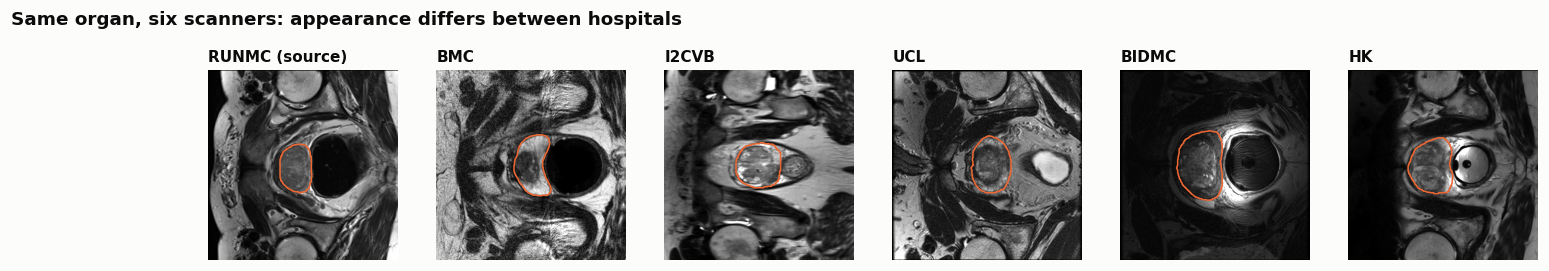

In [19]:
# One mid-prostate slice per hospital, with the ground-truth outline: the domain shift is visible.
sites_present = [s for s in KNOWN_SITES if s in site_dirs]
fig, axes = plt.subplots(1, len(sites_present), figsize=(2.6 * len(sites_present), 2.9))
for ax, site in zip(np.atleast_1d(axes), sites_present):
    v = get_vol(site, cases[cases.site == site].case.iloc[0])
    zs = np.where(v["gt"].sum((1, 2)) > 0)[0]
    z = int(zs[len(zs) // 2]) if len(zs) else v["gt"].shape[0] // 2
    ax.imshow(v["img255"][z], cmap="gray"); ax.contour(v["gt"][z], levels=[0.5], colors=[C_ORANGE], linewidths=1)
    ax.set_title(site + (" (source)" if site == SOURCE_SITE else ""), fontsize=10); ax.axis("off")
fig.suptitle("Same organ, six scanners: appearance differs between hospitals", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig1_sites")

## 2 · Proposer: small 2D U-Net trained on one hospital

The proposer only has to say roughly *where* the prostate is. It is trained on RUNMC (80% of its volumes; 20% kept for validation) and never sees the test hospitals. In Phase 2 it is replaced by nnU-Net.

In [20]:
class DoubleConv(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class UNet2D(nn.Module):
    def __init__(self, base=32, depth=4):
        super().__init__()
        ch = [base * 2 ** i for i in range(depth + 1)]
        self.down = nn.ModuleList([DoubleConv(1, ch[0])] + [DoubleConv(ch[i], ch[i + 1]) for i in range(depth)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in reversed(range(depth))])
        self.dec = nn.ModuleList([DoubleConv(ch[i] * 2, ch[i]) for i in reversed(range(depth))])
        self.head = nn.Conv2d(ch[0], 1, 1)
    def forward(self, x):
        skips = []
        for i, blk in enumerate(self.down):
            x = blk(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)
        x = skips.pop()
        for up, dec in zip(self.up, self.dec):
            x = dec(torch.cat([up(x), skips.pop()], 1))
        return self.head(x)

def zscore(img255):
    return (img255 - img255.mean()) / (img255.std() + 1e-6)

def volume_to_tensor(img255, gt=None):
    x = torch.from_numpy(zscore(img255))[:, None]
    x = F.interpolate(x, size=(UNET_SIZE, UNET_SIZE), mode="bilinear", align_corners=False)
    y = None
    if gt is not None:
        y = F.interpolate(torch.from_numpy(gt.astype(np.float32))[:, None], size=(UNET_SIZE, UNET_SIZE), mode="nearest")
    return x, y

src_cases = sorted(cases[cases.site == SOURCE_SITE].case)
rng_split = np.random.default_rng(0)
val_cases = sorted(rng_split.choice(src_cases, size=max(1, round(0.2 * len(src_cases))), replace=False).tolist())
train_cases = [c for c in src_cases if c not in val_cases]
Xtr, Ytr = zip(*[volume_to_tensor(get_vol(SOURCE_SITE, c)["img255"], get_vol(SOURCE_SITE, c)["gt"]) for c in train_cases])
Xtr, Ytr = torch.cat(Xtr), torch.cat(Ytr)
print(f"Proposer training: {len(train_cases)} RUNMC volumes, {len(Xtr)} slices | validation: {len(val_cases)} volumes")

Proposer training: 24 RUNMC volumes, 466 slices | validation: 6 volumes


In [21]:
@torch.no_grad()
def predict_volume(model, img255):
    model.eval()
    x, _ = volume_to_tensor(img255)
    probs = []
    for i in range(0, len(x), 32):
        probs.append(torch.sigmoid(model(x[i:i + 32].to(DEVICE))).float().cpu())
    p = F.interpolate(torch.cat(probs), size=img255.shape[1:], mode="bilinear", align_corners=False)[:, 0]
    return p.numpy()

def dice3d(a, b):
    a, b = a.astype(bool), b.astype(bool)
    s = a.sum() + b.sum()
    return 1.0 if s == 0 else 2.0 * (a & b).sum() / s

set_seed(0)
unet = UNet2D(UNET_BASE).to(DEVICE)
opt = torch.optim.AdamW(unet.parameters(), lr=UNET_LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=UNET_EPOCHS)
hist, best_val, best_state = [], -1, None
t0 = time.time()
for ep in range(1, UNET_EPOCHS + 1):
    unet.train(); perm = torch.randperm(len(Xtr)); losses = []
    for i in range(0, len(perm), UNET_BATCH):
        idx = perm[i:i + UNET_BATCH]
        x, y = Xtr[idx].to(DEVICE), Ytr[idx].to(DEVICE)
        if random.random() < 0.5: x, y = x.flip(-1), y.flip(-1)                      # left-right flip
        x = x * torch.empty(len(x), 1, 1, 1, device=DEVICE).uniform_(0.85, 1.15) \
              + torch.empty(len(x), 1, 1, 1, device=DEVICE).uniform_(-0.15, 0.15)    # intensity jitter
        logit = unet(x); p = torch.sigmoid(logit)
        dice_loss = 1 - (2 * (p * y).sum((1, 2, 3)) + 1) / (p.sum((1, 2, 3)) + y.sum((1, 2, 3)) + 1)
        loss = F.binary_cross_entropy_with_logits(logit, y) + dice_loss.mean()
        opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    sched.step()
    row = dict(epoch=ep, train_loss=float(np.mean(losses)), val_dice=np.nan)
    if ep % 5 == 0 or ep == UNET_EPOCHS:
        row["val_dice"] = float(np.mean([dice3d(predict_volume(unet, get_vol(SOURCE_SITE, c)["img255"]) > 0.5,
                                                get_vol(SOURCE_SITE, c)["gt"]) for c in val_cases]))
        if row["val_dice"] > best_val:
            best_val, best_state = row["val_dice"], {k: v.detach().clone() for k, v in unet.state_dict().items()}
        print(f"epoch {ep:3d}  loss {row['train_loss']:.3f}  val 3D Dice {row['val_dice']:.3f}  ({time.time() - t0:.0f}s)")
    hist.append(row)
unet.load_state_dict(best_state)
pd.DataFrame(hist).to_csv(OUT / "proposer_training.csv", index=False)
print(f"Best RUNMC validation 3D Dice: {best_val:.3f}")

epoch   5  loss 0.957  val 3D Dice 0.733  (44s)
epoch  10  loss 0.634  val 3D Dice 0.747  (87s)
epoch  15  loss 0.523  val 3D Dice 0.699  (132s)
epoch  20  loss 0.451  val 3D Dice 0.811  (176s)
epoch  25  loss 0.387  val 3D Dice 0.786  (222s)
epoch  30  loss 0.388  val 3D Dice 0.844  (267s)
epoch  35  loss 0.359  val 3D Dice 0.835  (312s)
epoch  40  loss 0.356  val 3D Dice 0.835  (358s)
Best RUNMC validation 3D Dice: 0.844


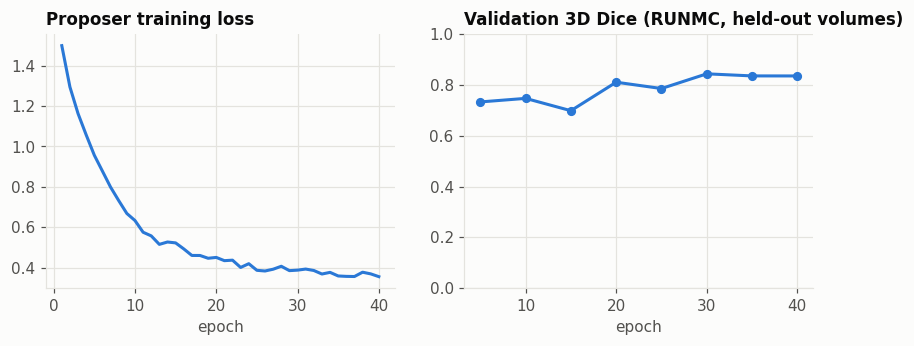

In [22]:
h = pd.DataFrame(hist)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3))
a1.plot(h.epoch, h.train_loss, color=C_NIC, lw=2); a1.set_title("Proposer training loss"); a1.set_xlabel("epoch")
hv = h.dropna(subset=["val_dice"])
a2.plot(hv.epoch, hv.val_dice, color=C_NIC, lw=2, marker="o", ms=5); a2.set_ylim(0, 1)
a2.set_title("Validation 3D Dice (RUNMC, held-out volumes)"); a2.set_xlabel("epoch")
savefig(fig, "fig2_proposer_training")

## 3 · Test volumes and MedSAM (frozen)

MedSAM's image encoder runs **once per slice** and the embedding is cached; the light mask decoder is then called once per box. Preprocessing copies MedSAM's own inference code (3 channels, 1024×1024, min-max to [0, 1]).

In [23]:
test_list = []
for site in TEST_SITES:
    if site not in site_dirs:
        print(f"Skipping {site}: not found"); continue
    cs = sorted(cases[cases.site == site].case)
    if N_TEST_PER_SITE is not None and len(cs) > N_TEST_PER_SITE:
        cs = sorted(np.random.default_rng(1).choice(cs, N_TEST_PER_SITE, replace=False).tolist())
    test_list += [(site, c) for c in cs]
print(len(test_list), "test volumes:", test_list)

for key in test_list:
    v = get_vol(*key)
    v["prob"] = predict_volume(unet, v["img255"])
    v["proposer_dice"] = dice3d(v["prob"] > 0.5, v["gt"])
pd.DataFrame([dict(site=s, case=c, proposer_dice=VOLS[(s, c)]["proposer_dice"]) for s, c in test_list]).groupby("site").proposer_dice.mean()

12 test volumes: [('BMC', 'Case12'), ('BMC', 'Case14'), ('BMC', 'Case21'), ('BMC', 'Case28'), ('BIDMC', 'Case05'), ('BIDMC', 'Case06'), ('BIDMC', 'Case09'), ('BIDMC', 'Case12'), ('HK', 'Case42'), ('HK', 'Case43'), ('HK', 'Case46'), ('HK', 'Case49')]


site
BIDMC    0.357682
BMC      0.602951
HK       0.835938
Name: proposer_dice, dtype: float64

In [24]:
from segment_anything import sam_model_registry
import hashlib

def find_ckpt():
    # Looks in WORK and in Kaggle inputs (an uploaded dataset); ignores partial downloads (< 300 MB)
    roots = [WORK] + ([Path("/kaggle/input")] if Path("/kaggle/input").exists() else [])
    if CKPT_PATH.exists() and CKPT_PATH.stat().st_size > 300e6:
        return CKPT_PATH
    for root in roots:
        for h in root.rglob("medsam*vit_b*.pth"):
            if h.stat().st_size > 300e6:
                return h
    return None

ckpt, CKPT_SOURCE = find_ckpt(), "found on disk"
if ckpt is None:
    try:                                               # 1) official file, single-file download
        import gdown
        print("Downloading medsam_vit_b.pth from the official MedSAM Google Drive (~375 MB) ...")
        gdown.download(id=MEDSAM_GDRIVE_FILE_ID, output=str(CKPT_PATH), quiet=False)
        ckpt, CKPT_SOURCE = find_ckpt(), "official Google Drive"
    except Exception as e:
        print("Google Drive refused the download:", str(e).splitlines()[0])
if ckpt is None:
    try:                                               # 2) community mirror
        print("Trying the Hugging Face mirror ...")
        if CKPT_PATH.exists(): CKPT_PATH.unlink()
        torch.hub.download_url_to_file(MEDSAM_MIRROR_URL, str(CKPT_PATH), progress=True)
        ckpt, CKPT_SOURCE = find_ckpt(), "Hugging Face mirror (unofficial)"
    except Exception as e:
        print("Mirror download failed:", e)
assert ckpt is not None, (
    "Could not get medsam_vit_b.pth automatically. Open "
    f"https://drive.google.com/file/d/{MEDSAM_GDRIVE_FILE_ID}/view in your browser, download it, "
    "add it to this notebook as a Kaggle dataset (Add Input > Upload), and re-run this cell.")

sha = hashlib.sha256()
with open(ckpt, "rb") as fh:
    for chunk in iter(lambda: fh.read(1 << 22), b""): sha.update(chunk)
CKPT_SHA256 = sha.hexdigest()

medsam = sam_model_registry["vit_b"]()
state = torch.load(ckpt, map_location="cpu", weights_only=True)   # weights only: safe even for a mirror file
medsam.load_state_dict(state.get("model", state) if isinstance(state, dict) and "model" in state else state)
medsam = medsam.to(DEVICE).eval()
print(f"MedSAM loaded from {ckpt}\n  source: {CKPT_SOURCE}\n  sha256: {CKPT_SHA256}")

@torch.no_grad()
def encode_volume(img255):
    out = []
    for sl in img255:
        img3 = np.repeat(sl[..., None], 3, axis=-1)
        img1024 = sk_transform.resize(img3, (1024, 1024), order=3, preserve_range=True, anti_aliasing=True)
        img1024 = (img1024 - img1024.min()) / np.clip(img1024.max() - img1024.min(), 1e-8, None)
        t = torch.from_numpy(img1024).float().permute(2, 0, 1)[None].to(DEVICE)
        out.append(medsam.image_encoder(t).half().cpu())
    return torch.cat(out)          # (D, 256, 64, 64)

DECODER_CALLS = {"n": 0}

@torch.no_grad()
def decode(emb, boxes, H, W):
    # emb: (256,64,64) cached embedding; boxes: (B,4) x0,y0,x1,y1 in image pixels.
    # Returns masks (B,H,W) bool, predicted IoU (B,), stability score (B,).
    boxes = np.asarray(boxes, dtype=np.float32).reshape(-1, 4)
    b = torch.from_numpy(boxes).to(DEVICE) / torch.tensor([W, H, W, H], device=DEVICE, dtype=torch.float32) * 1024
    sparse, dense = medsam.prompt_encoder(points=None, boxes=b[:, None, :], masks=None)
    logits, iou = medsam.mask_decoder(image_embeddings=emb[None].float().to(DEVICE),
                                      image_pe=medsam.prompt_encoder.get_dense_pe(),
                                      sparse_prompt_embeddings=sparse, dense_prompt_embeddings=dense,
                                      multimask_output=False)
    stab = (logits > 1.0).sum((1, 2, 3)).float() / (logits > -1.0).sum((1, 2, 3)).clamp(min=1).float()
    prob = F.interpolate(torch.sigmoid(logits), size=(H, W), mode="bilinear", align_corners=False)[:, 0]
    DECODER_CALLS["n"] += len(boxes)
    return (prob > 0.5).cpu().numpy(), iou[:, 0].float().cpu().numpy(), stab.cpu().numpy()

t0 = time.time()
for i, key in enumerate(test_list):
    v = VOLS[key]
    v["emb"] = encode_volume(v["img255"])
    print(f"[{i + 1}/{len(test_list)}] encoded {key} ({len(v['emb'])} slices, {time.time() - t0:.0f}s)")

# Sanity check: MedSAM with the true box on the largest slice should be accurate
v = VOLS[test_list[0]]; z = int(v["gt"].sum((1, 2)).argmax())
ys, xs = np.where(v["gt"][z])
m, iou_p, _ = decode(v["emb"][z], [[xs.min(), ys.min(), xs.max(), ys.max()]], *v["gt"].shape[1:])
sanity = dice3d(m[0], v["gt"][z])
print(f"Sanity check, true box on {test_list[0]} slice {z}: 2D Dice {sanity:.3f} (predicted IoU {iou_p[0]:.2f})")
if sanity < 0.7:
    print("WARNING: MedSAM is much worse than expected with a perfect box. Check the checkpoint "
          "(source and sha256 above) before trusting any result below.")

MedSAM loaded from /kaggle/working/pherosam/medsam_vit_b.pth
  source: found on disk
  sha256: 34b34b78c1d18cb8c6bf84cf9c00e135d6d6c965699f3c0e31ef1bc9dcb5be74
[1/12] encoded ('BMC', 'Case12') (32 slices, 80s)
[2/12] encoded ('BMC', 'Case14') (32 slices, 160s)
[3/12] encoded ('BMC', 'Case21') (32 slices, 242s)
[4/12] encoded ('BMC', 'Case28') (32 slices, 324s)
[5/12] encoded ('BIDMC', 'Case05') (42 slices, 432s)
[6/12] encoded ('BIDMC', 'Case06') (39 slices, 532s)
[7/12] encoded ('BIDMC', 'Case09') (47 slices, 652s)
[8/12] encoded ('BIDMC', 'Case12') (46 slices, 769s)
[9/12] encoded ('HK', 'Case42') (24 slices, 830s)
[10/12] encoded ('HK', 'Case43') (24 slices, 891s)
[11/12] encoded ('HK', 'Case46') (24 slices, 952s)
[12/12] encoded ('HK', 'Case49') (24 slices, 1011s)
Sanity check, true box on ('BMC', 'Case12') slice 13: 2D Dice 0.956 (predicted IoU 0.57)


## 4 · Candidate boxes and the slice graph

For every slice in the search window: threshold the proposer map at 0.5 / 0.3 / 0.7, take the largest component's box, add a 0 px and a 6 px margin version, remove near-duplicates (box IoU > 0.9), keep at most 5, and add a **"no object"** node. Each box is decoded once by MedSAM; all masks are cached.

- **Node confidence η** = MedSAM predicted IoU (or stability score); for "no object" it is 1 − (max proposer probability on that slice).
- **Edge smoothness κ** = IoU between the two masks when both slices hold an object; any transition involving "no object" gets a neutral 0.5 (`KAPPA_EMPTY`), so empty predictions are never rewarded for being "smooth". Two virtual empty nodes before and after the window let the colony decide where the organ starts and ends.

In [25]:
def bbox(mask, margin=0, shape=None):
    ys, xs = np.where(mask)
    if len(ys) == 0: return None
    H, W = shape if shape is not None else mask.shape
    return np.array([max(xs.min() - margin, 0), max(ys.min() - margin, 0),
                     min(xs.max() + margin, W - 1), min(ys.max() + margin, H - 1)], dtype=np.float32)

def box_iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy; ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def largest_cc(mask):
    lab, n = ndimage.label(mask)
    if n == 0: return mask
    sizes = ndimage.sum(mask, lab, range(1, n + 1))
    return lab == (int(np.argmax(sizes)) + 1)

def slice_candidates(prob2d):
    boxes, types = [], []
    for thr in THRESHOLDS:
        m = largest_cc(prob2d > thr)
        if m.sum() < MIN_AREA: continue
        for mg in MARGINS:
            b = bbox(m, mg, prob2d.shape)
            if all(box_iou(b, o) <= 0.9 for o in boxes):
                boxes.append(b); types.append(f"t{thr}_m{mg}")
    return boxes[:K_MAX], types[:K_MAX]

def mask_iou(a, b):
    u = (a | b).sum()
    return 1.0 if u == 0 else (a & b).sum() / u

def slice_dice(a, b):
    s = a.sum() + b.sum()
    return 1.0 if s == 0 else 2.0 * (a & b).sum() / s

def build_graph(v):
    D, H, W = v["gt"].shape
    maxp = v["prob"].reshape(D, -1).max(1)
    on = np.where(maxp > WINDOW_THR)[0]
    v["window"] = None if len(on) == 0 else (max(on.min() - WINDOW_EXTEND, 0), min(on.max() + WINDOW_EXTEND, D - 1))
    v["nodes"], v["cand_calls"] = [], 0
    if v["window"] is None:
        return v
    s, e = v["window"]
    for d in range(s, e + 1):
        boxes, types = slice_candidates(v["prob"][d])
        masks = [np.zeros((H, W), bool)]; conf = [1.0 - float(maxp[d])]
        if boxes:
            m, iou_p, stab = decode(v["emb"][d], np.stack(boxes), H, W)
            v["cand_calls"] += len(boxes)
            masks += list(m); conf += list(iou_p if CONF_SOURCE == "iou_pred" else stab)
        v["nodes"].append(dict(d=d, boxes=[None] + boxes, types=["empty"] + types, masks=np.stack(masks),
                               conf=np.array(conf, dtype=np.float64),
                               true_dice=np.array([slice_dice(mk, v["gt"][d].astype(bool)) for mk in masks])))
    # Padded arrays for fast vectorised scoring:
    #   C[t, j]      confidence of node j on window slice t   (-inf where node j does not exist)
    #   K[t, i, j]   smoothness of transition t (t = 0..L): node i before -> node j after
    L = len(v["nodes"]); n = [len(nd["conf"]) for nd in v["nodes"]]; nmax = max(n)
    C = np.full((L, nmax), -np.inf); K = np.zeros((L + 1, nmax, nmax))
    for t, nd in enumerate(v["nodes"]):
        C[t, :n[t]] = nd["conf"]
    flat = [nd["masks"].reshape(len(nd["masks"]), -1) for nd in v["nodes"]]
    K[0, 0, :n[0]] = KAPPA_EMPTY                              # virtual empty -> first slice
    for t in range(1, L):
        A, B = flat[t - 1], flat[t]
        inter = A.astype(np.float32) @ B.T.astype(np.float32)
        union = A.sum(1)[:, None] + B.sum(1)[None] - inter
        K[t, :n[t - 1], :n[t]] = np.where(union > 0, inter / np.maximum(union, 1), 1.0)
        K[t, 0, :n[t]] = KAPPA_EMPTY; K[t, :n[t - 1], 0] = KAPPA_EMPTY   # transitions with "no object"
    K[L, :n[L - 1], 0] = KAPPA_EMPTY                          # last slice -> virtual empty
    v["L"], v["n"], v["C"], v["K"] = L, np.array(n), C, K
    return v

t0 = time.time()
for key in test_list:
    build_graph(VOLS[key])
gstats = []
for s, c in test_list:
    v = VOLS[(s, c)]
    gt_z = np.where(v["gt"].sum((1, 2)) > 0)[0]
    good = [nd["true_dice"][1:].max(initial=0) >= 0.7 for nd in v["nodes"] if v["gt"][nd["d"]].any()]
    gstats.append(dict(site=s, case=c, slices=v["gt"].shape[0], window=v["window"], prostate_slices=len(gt_z),
                       nodes_per_slice=float(np.mean(v["n"])) if v["nodes"] else 0, decoder_calls=v["cand_calls"],
                       candidate_recall=float(np.mean(good)) if good else 0.0))
gstats = pd.DataFrame(gstats)
print(f"Graphs built in {time.time() - t0:.0f}s")
gstats

Graphs built in 7s


,site,case,slices,window,prostate_slices,nodes_per_slice,decoder_calls,candidate_recall
0,BMC,Case12,32,"(0, 17)",11,2.888889,34,0.636364
1,BMC,Case14,32,"(0, 31)",12,2.562500,50,0.666667
2,BMC,Case21,32,"(2, 31)",16,3.266667,68,0.375000
3,BMC,Case28,32,"(3, 31)",13,2.931034,56,0.384615
4,BIDMC,Case05,42,"(4, 41)",26,2.447368,55,0.000000
5,BIDMC,Case06,39,"(0, 38)",29,3.153846,84,0.379310
6,BIDMC,Case09,47,"(0, 46)",26,3.319149,109,0.461538
7,BIDMC,Case12,46,"(5, 42)",22,3.052632,78,0.090909
8,HK,Case42,24,"(1, 23)",22,3.000000,46,0.954545
9,HK,Case43,24,"(0, 17)",14,3.055556,37,0.714286


## 5 · Methods

All selection methods share the same cached candidates and the same fitness:

$$F(\pi) = w_c\,\overline{\text{Conf}}(\pi) + w_s\,\overline{\text{Smooth}}(\pi) - w_p\,\text{Pen}(\pi)$$

where Pen = number of extra disconnected pieces along the slice axis (a *global* term, switched off in the main run). The MMAS transition rule is

$$p_{ij}^{(d)} = \frac{(\tau_{ij}^{(d)})^{\alpha}\,(\eta_j^{(d)})^{\beta}\,(\kappa_{ij}^{(d)}+\epsilon)^{\gamma}}{\sum_l (\tau_{il}^{(d)})^{\alpha}\,(\eta_l^{(d)})^{\beta}\,(\kappa_{il}^{(d)}+\epsilon)^{\gamma}}$$

with evaporation ρ, best-ant deposit (iteration-best, then global-best) and pheromone clipped to [τ_min, τ_max] as in Stützle & Hoos (2000). **MMAS + DP seed** starts with the DP path's edges at τ_max and every other edge at 0.5·τ_max.

In [26]:
def fitness(v, paths, w_pen=None):
    # paths: (A, L) node indices -> fitness (A,)
    w_pen = W_PEN if w_pen is None else w_pen
    paths = np.atleast_2d(paths); A, L = paths.shape
    conf = v["C"][np.arange(L)[None], paths].mean(1)
    ext = np.concatenate([np.zeros((A, 1), int), paths, np.zeros((A, 1), int)], 1)
    smooth = v["K"][np.arange(L + 1)[None], ext[:, :-1], ext[:, 1:]].mean(1)
    runs = ((ext[:, :-1] == 0) & (ext[:, 1:] != 0)).sum(1)
    pen = np.maximum(runs - 1, 0)
    return W_CONF * conf + W_SMOOTH * smooth - w_pen * pen

def path_to_mask(v, path):
    out = np.zeros(v["gt"].shape, bool)
    for t, j in enumerate(path):
        if j > 0: out[v["nodes"][t]["d"]] = v["nodes"][t]["masks"][j]
    return out

# --- baselines -------------------------------------------------------------------
def best_box_path(v):
    return np.nanargmax(v["C"], 1)

def oracle_selection_path(v):
    return np.array([int(np.lexsort((nd["conf"], nd["true_dice"]))[-1]) for nd in v["nodes"]])

def dp_viterbi(v):
    # Exact maximiser of the LOCAL fitness (W_PEN ignored, as DP cannot represent it).
    L, C, K = v["L"], v["C"], v["K"]
    a, b = W_CONF / L, W_SMOOTH / (L + 1)
    score = a * C[0] + b * K[0, 0]; back = []
    for t in range(1, L):
        cand = score[:, None] + b * K[t] + a * C[t][None]
        back.append(np.argmax(cand, 0)); score = cand.max(0)
    score = score + b * K[L, :, 0]
    j = int(np.argmax(score)); path = [j]
    for bp in reversed(back):
        j = int(bp[j]); path.append(j)
    return np.array(path[::-1])

def random_search(v, rng, n_eval):
    probs = np.isfinite(v["C"]).astype(float); probs /= probs.sum(1, keepdims=True)
    cum = probs.cumsum(1)
    paths = (rng.random((n_eval, v["L"], 1)) < cum[None]).argmax(2)
    f = fitness(v, paths)
    best_curve = np.maximum.accumulate(f)
    return paths[int(np.argmax(f))], best_curve

# --- MMAS ------------------------------------------------------------------------
def mmas(v, rng, seed_path=None, w_pen=None, n_ants=None, n_rounds=None):
    n_ants, n_rounds = n_ants or N_ANTS, n_rounds or N_ROUNDS
    L, n, C, K = v["L"], v["n"], v["C"], v["K"]
    eta = np.where(np.isfinite(C), np.maximum(C, 1e-3), 0.0) ** BETA                  # (L, nmax)
    kap = (K + KAPPA_EPS) ** GAMMA
    start = seed_path if seed_path is not None else best_box_path(v)
    gb_path = start.copy(); gb_f = float(fitness(v, start, w_pen)[0])
    avg = max(float(np.mean(n)), 1.0001); pdec = P_BEST ** (1.0 / L)
    def limits(fbest):
        tmax = max(fbest, 1e-6) / RHO
        return tmax * min(0.99, (1 - pdec) / ((avg - 1) * pdec)), tmax
    tmin, tmax = limits(gb_f)
    tau = np.full(K.shape, tmax)
    if seed_path is not None:
        tau[:] = TAU_SEED_FRAC * tmax
        ext = np.r_[0, seed_path, 0]
        tau[np.arange(L + 1), ext[:-1], ext[1:]] = tmax
    curve, stall = [], 0
    for r in range(n_rounds):
        paths = np.zeros((n_ants, L), int); cur = np.zeros(n_ants, int)
        for t in range(L):
            Wt = (tau[t] ** ALPHA) * kap[t] * eta[t][None]                            # (nmax_prev, nmax)
            P = Wt[cur]; P = P / P.sum(1, keepdims=True)
            cur = (rng.random((n_ants, 1)) < P.cumsum(1)).argmax(1)
            paths[:, t] = cur
        f = fitness(v, paths, w_pen)
        ib = int(np.argmax(f))
        curve.extend(np.maximum.accumulate(np.maximum(f, gb_f if r else -np.inf)).tolist())
        if f[ib] > gb_f + 1e-12:
            gb_f, gb_path, stall = float(f[ib]), paths[ib].copy(), 0
        else:
            stall += 1
        dep_path, dep_f = (paths[ib], f[ib]) if r < GB_SWITCH else (gb_path, gb_f)
        tau *= (1 - RHO)
        ext = np.r_[0, dep_path, 0]
        tau[np.arange(L + 1), ext[:-1], ext[1:]] += dep_f
        tmin, tmax = limits(gb_f)
        np.clip(tau, tmin, tmax, out=tau)
        if stall >= PATIENCE: break
    # pheromone spread per slice (normalised entropy of incoming pheromone): high = colony disagrees
    ent = []
    for t in range(L):
        q = tau[t][:, :n[t]].sum(0); q = q / q.sum()
        ent.append(float(-(q * np.log(q + 1e-12)).sum() / np.log(n[t])) if n[t] > 1 else 0.0)
    return gb_path, np.array(curve), np.array(ent)

# --- greedy propagation (needs new decoder calls) ---------------------------------
def greedy_propagation(v):
    D, H, W = v["gt"].shape
    out = np.zeros((D, H, W), bool); calls0 = DECODER_CALLS["n"]
    if v["window"] is None:
        return out, 0
    t_star = int(np.argmax([v["prob"][nd["d"]].max() for nd in v["nodes"]]))
    nd = v["nodes"][t_star]
    if len(nd["conf"]) < 2:
        return out, 0
    j = 1 + int(np.argmax(nd["conf"][1:]))
    out[nd["d"]] = nd["masks"][j]
    for step in (1, -1):
        prev, d = out[nd["d"]], nd["d"] + step
        while 0 <= d < D and prev.sum() >= MIN_AREA:
            b = bbox(prev, GREEDY_MARGIN, (H, W))
            m, _, _ = decode(v["emb"][d], b[None], H, W)
            if m[0].sum() < MIN_AREA: break
            out[d] = m[0]; prev = m[0]; d += step
    return out, DECODER_CALLS["n"] - calls0

def oracle_boxes(v):
    D, H, W = v["gt"].shape
    out = np.zeros((D, H, W), bool); calls0 = DECODER_CALLS["n"]
    for d in np.where(v["gt"].sum((1, 2)) > 0)[0]:
        m, _, _ = decode(v["emb"][d], bbox(v["gt"][d], 0)[None], H, W)
        out[d] = m[0]
    return out, DECODER_CALLS["n"] - calls0

## 6 · Run every method on every test volume

Metrics per volume: **3D Dice**, **HD95** (mm), **pieces** (separate parts of the mask along the slice axis; 1 is ideal), **jumps** (neighbouring slices whose masks overlap with IoU < 0.5), the **label-free fitness F**, runtime, and MedSAM **decoder calls**. Stochastic methods run with every seed in `SEEDS`.

In [27]:
def hd95(a, b, spacing):
    a, b = a.astype(bool), b.astype(bool)
    if not a.any() or not b.any(): return np.nan
    zz, yy, xx = np.where(a | b)
    sl = tuple(slice(max(lo - 2, 0), hi + 3) for lo, hi in ((zz.min(), zz.max()), (yy.min(), yy.max()), (xx.min(), xx.max())))
    a, b = a[sl], b[sl]
    sa, sb = a ^ ndimage.binary_erosion(a), b ^ ndimage.binary_erosion(b)
    da = ndimage.distance_transform_edt(~sb, sampling=spacing)[sa]
    db = ndimage.distance_transform_edt(~sa, sampling=spacing)[sb]
    return float(max(np.percentile(da, 95), np.percentile(db, 95)))

def pieces_and_jumps(mask):
    on = mask.reshape(len(mask), -1).any(1)
    pieces = int(((~np.r_[False, on[:-1]]) & on).sum())
    jumps = sum(1 for d in range(1, len(mask)) if on[d] and on[d - 1] and mask_iou(mask[d], mask[d - 1]) < 0.5)
    return pieces, jumps

METHODS = ["Proposer only", "MedSAM best box", "MedSAM greedy propagation", "Random search", "DP (Viterbi)",
           "MMAS", "MMAS + DP seed", "Oracle selection", "Oracle boxes"]
rows, PRED, CURVES, ENTROPY = [], {}, {"MMAS": [], "Random search": []}, {}
n_eval = N_ANTS * N_ROUNDS

def record(key, method, seed, mask, secs, calls, f=np.nan):
    v = VOLS[key]; pc, jp = pieces_and_jumps(mask)
    rows.append(dict(site=key[0], case=key[1], method=method, seed=seed, dice=dice3d(mask, v["gt"]),
                     hd95=hd95(mask, v["gt"], v["spacing"]), pieces=pc, jumps=jp, fitness=f,
                     seconds=secs, decoder_calls=calls))
    if seed in (None, SEEDS[0]): PRED[(key, method)] = np.packbits(mask)

t_all = time.time()
for i, key in enumerate(test_list):
    v = VOLS[key]
    record(key, "Proposer only", None, v["prob"] > 0.5, 0.0, 0)
    t = time.time(); m, calls = greedy_propagation(v); record(key, "MedSAM greedy propagation", None, m, time.time() - t, calls)
    t = time.time(); m, calls = oracle_boxes(v); record(key, "Oracle boxes", None, m, time.time() - t, calls)
    if v["window"] is None:                      # proposer found nothing: every selection method returns empty
        empty = np.zeros(v["gt"].shape, bool)
        for meth in ["MedSAM best box", "DP (Viterbi)", "Oracle selection"]:
            record(key, meth, None, empty, 0.0, 0)
        for meth in ["Random search", "MMAS", "MMAS + DP seed"]:
            for s in SEEDS: record(key, meth, s, empty, 0.0, 0)
        continue
    cc = v["cand_calls"]
    for meth, fn in [("MedSAM best box", best_box_path), ("DP (Viterbi)", dp_viterbi), ("Oracle selection", oracle_selection_path)]:
        t = time.time(); p = fn(v); secs = time.time() - t
        record(key, meth, None, path_to_mask(v, p), secs, cc, float(fitness(v, p)[0]))
    v["dp_path"] = dp_viterbi(v); f_dp = float(fitness(v, v["dp_path"])[0])
    for s in SEEDS:
        rng = np.random.default_rng(s)
        t = time.time(); p, curve = random_search(v, rng, n_eval); secs = time.time() - t
        record(key, "Random search", s, path_to_mask(v, p), secs, cc, float(fitness(v, p)[0]))
        CURVES["Random search"].append(curve / f_dp)
        t = time.time(); p, curve, ent = mmas(v, rng); secs = time.time() - t
        record(key, "MMAS", s, path_to_mask(v, p), secs, cc, float(fitness(v, p)[0]))
        CURVES["MMAS"].append(curve / f_dp)
        if s == SEEDS[0]: ENTROPY[key] = ent
        t = time.time(); p, _, _ = mmas(v, rng, seed_path=v["dp_path"]); secs = time.time() - t
        record(key, "MMAS + DP seed", s, path_to_mask(v, p), secs, cc, float(fitness(v, p)[0]))
    print(f"[{i + 1}/{len(test_list)}] {key} done ({time.time() - t_all:.0f}s)")

res = pd.DataFrame(rows)
res.to_csv(OUT / "results_per_volume_and_seed.csv", index=False)
print("Saved", OUT / "results_per_volume_and_seed.csv")

[1/12] ('BMC', 'Case12') done (2s)
[2/12] ('BMC', 'Case14') done (5s)
[3/12] ('BMC', 'Case21') done (9s)
[4/12] ('BMC', 'Case28') done (11s)
[5/12] ('BIDMC', 'Case05') done (17s)
[6/12] ('BIDMC', 'Case06') done (24s)
[7/12] ('BIDMC', 'Case09') done (32s)
[8/12] ('BIDMC', 'Case12') done (38s)
[9/12] ('HK', 'Case42') done (40s)
[10/12] ('HK', 'Case43') done (41s)
[11/12] ('HK', 'Case46') done (43s)
[12/12] ('HK', 'Case49') done (45s)
Saved /kaggle/working/pherosam/outputs/results_per_volume_and_seed.csv


## 7 · Results table and statistics

Stochastic methods are first averaged over seeds per volume, then summarised over volumes (mean ± std). The Wilcoxon signed-rank test compares **MMAS** with each other method on per-volume 3D Dice, with Holm correction. With ~12 volumes this is a low-power test; report it as preliminary.

In [28]:
per_vol = (res.groupby(["site", "case", "method"], as_index=False)
              .agg(dice=("dice", "mean"), hd95=("hd95", "mean"), pieces=("pieces", "mean"), jumps=("jumps", "mean"),
                   fitness=("fitness", "mean"), seconds=("seconds", "mean"), decoder_calls=("decoder_calls", "mean")))
per_vol.to_csv(OUT / "results_per_volume.csv", index=False)

def mstd(x, nd=3):
    x = x.dropna()
    if len(x) == 0: return "–"
    return f"{x.mean():.{nd}f} ± {x.std(ddof=1):.{nd}f}" if len(x) > 1 else f"{x.mean():.{nd}f}"

recs = []
for m in METHODS:
    g = per_vol[per_vol.method == m]
    if len(g) == 0: continue
    recs.append({"method": m, "3D Dice": mstd(g.dice), "HD95 (mm)": mstd(g.hd95, 1),
                 "HD95 missing (empty masks)": int(g.hd95.isna().sum()),
                 "pieces": f"{g.pieces.mean():.2f}", "jumps": f"{g.jumps.mean():.2f}", "fitness F": mstd(g.fitness),
                 "decoder calls": f"{g.decoder_calls.mean():.0f}", "seconds": f"{g.seconds.mean():.2f}"})
main_table = pd.DataFrame(recs).set_index("method")
main_table.to_csv(OUT / "table_main_results.csv")
main_table

,3D Dice,HD95 (mm),HD95 missing (empty masks),pieces,jumps,fitness F,decoder calls,seconds
method,,,,,,,,
Proposer only,0.599 ± 0.230,26.2 ± 16.6,0,2.17,4.67,–,0,0.00
MedSAM best box,0.595 ± 0.246,25.0 ± 17.4,0,2.17,5.92,1.213 ± 0.081,60,0.00
MedSAM greedy propagation,0.520 ± 0.275,30.1 ± 14.4,0,1.00,1.42,–,32,0.28
Random search,0.587 ± 0.248,24.2 ± 17.0,0,3.22,4.17,1.188 ± 0.068,60,0.00
DP (Viterbi),0.603 ± 0.249,24.8 ± 17.7,0,2.75,3.08,1.256 ± 0.066,60,0.00
MMAS,0.602 ± 0.251,24.6 ± 17.4,0,2.39,3.94,1.246 ± 0.071,60,0.02
MMAS + DP seed,0.603 ± 0.249,24.8 ± 17.7,0,2.75,3.08,1.256 ± 0.066,60,0.01
Oracle selection,0.650 ± 0.256,15.6 ± 13.9,0,1.08,2.67,1.137 ± 0.110,60,0.00
Oracle boxes,0.888 ± 0.024,4.3 ± 1.3,0,1.00,1.67,–,18,0.14


In [29]:
by_site = per_vol.pivot_table(index="method", columns="site", values="dice", aggfunc="mean").reindex(METHODS)
by_site["all"] = per_vol.groupby("method").dice.mean().reindex(METHODS)
by_site.round(3).to_csv(OUT / "table_dice_by_site.csv")

wide = per_vol.pivot_table(index=["site", "case"], columns="method", values="dice")
tests = []
for m in METHODS:
    if m == "MMAS" or m not in wide: continue
    d = (wide["MMAS"] - wide[m]).dropna()
    p = float(stats.wilcoxon(d, zero_method="zsplit").pvalue) if (d != 0).any() else 1.0
    tests.append(dict(comparison=f"MMAS vs {m}", mean_diff=d.mean(), p_raw=p))
tests = pd.DataFrame(tests).sort_values("p_raw").reset_index(drop=True)
k = len(tests); tests["p_holm"] = np.minimum(1, np.maximum.accumulate([(k - i) * p for i, p in enumerate(tests.p_raw)]))
tests["significant_0.05"] = tests.p_holm < 0.05
tests.to_csv(OUT / "table_wilcoxon_mmas.csv", index=False)
display(by_site.round(3)); display(tests.round(4))

site,BIDMC,BMC,HK,all
method,,,,
Proposer only,0.358,0.603,0.836,0.599
MedSAM best box,0.363,0.605,0.816,0.595
MedSAM greedy propagation,0.302,0.522,0.737,0.520
Random search,0.346,0.593,0.821,0.587
DP (Viterbi),0.365,0.610,0.833,0.603
MMAS,0.361,0.610,0.835,0.602
MMAS + DP seed,0.365,0.610,0.833,0.603
Oracle selection,0.407,0.672,0.872,0.650
Oracle boxes,0.881,0.909,0.873,0.888


,comparison,mean_diff,p_raw,p_holm,significant_0.05
0,MMAS vs Oracle selection,-0.0482,0.0005,0.0039,True
1,MMAS vs Oracle boxes,-0.2856,0.0005,0.0039,True
2,MMAS vs Random search,0.0155,0.0010,0.0059,True
3,MMAS vs MedSAM greedy propagation,0.0818,0.0161,0.0806,False
4,MMAS vs MedSAM best box,0.0073,0.0640,0.2559,False
5,MMAS vs Proposer only,0.0032,0.4697,1.0000,False
6,MMAS vs MMAS + DP seed,-0.0006,0.6772,1.0000,False
7,MMAS vs DP (Viterbi),-0.0006,0.6772,1.0000,False


## 8 · Figures

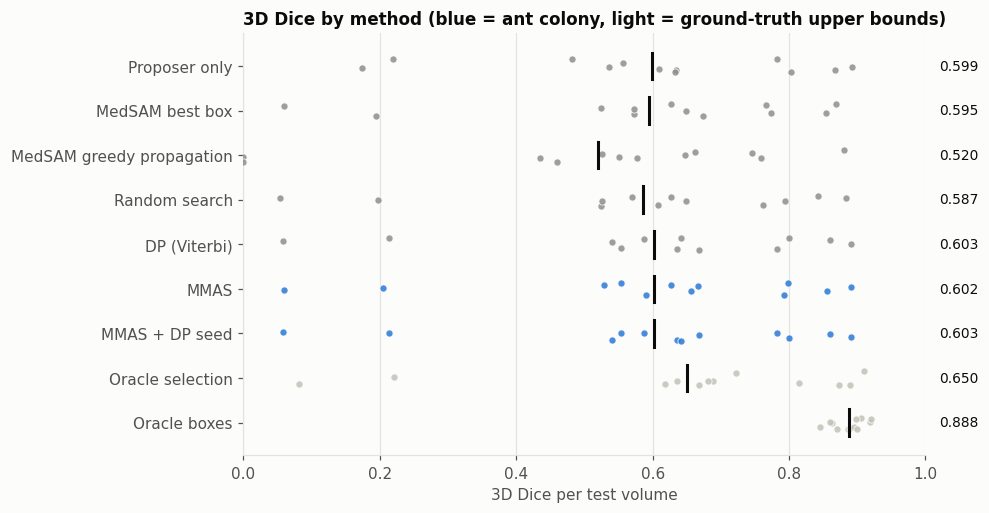

In [30]:
# Fig 3 — 3D Dice per method: one dot per test volume, black bar = mean
order = [m for m in METHODS if m in set(per_vol.method)]
col = {m: (C_NIC if m.startswith("MMAS") else C_BOUND if m.startswith("Oracle") else C_BASE) for m in order}
fig, ax = plt.subplots(figsize=(8, 0.42 * len(order) + 1.2))
rng_j = np.random.default_rng(0)
for y, m in enumerate(order):
    d = per_vol[per_vol.method == m].dice.values
    ax.scatter(d, y + rng_j.uniform(-0.16, 0.16, len(d)), s=22, color=col[m], alpha=0.85, edgecolor=SURF, linewidth=0.6, zorder=3)
    ax.plot([d.mean()] * 2, [y - 0.3, y + 0.3], color=INK, lw=2, zorder=4)
    ax.text(1.02, y, f"{d.mean():.3f}", va="center", fontsize=9, color=INK, transform=ax.get_yaxis_transform())
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.set_xlabel("3D Dice per test volume"); ax.grid(axis="y", visible=False)
ax.set_title("3D Dice by method (blue = ant colony, light = ground-truth upper bounds)")
savefig(fig, "fig3_dice_by_method")

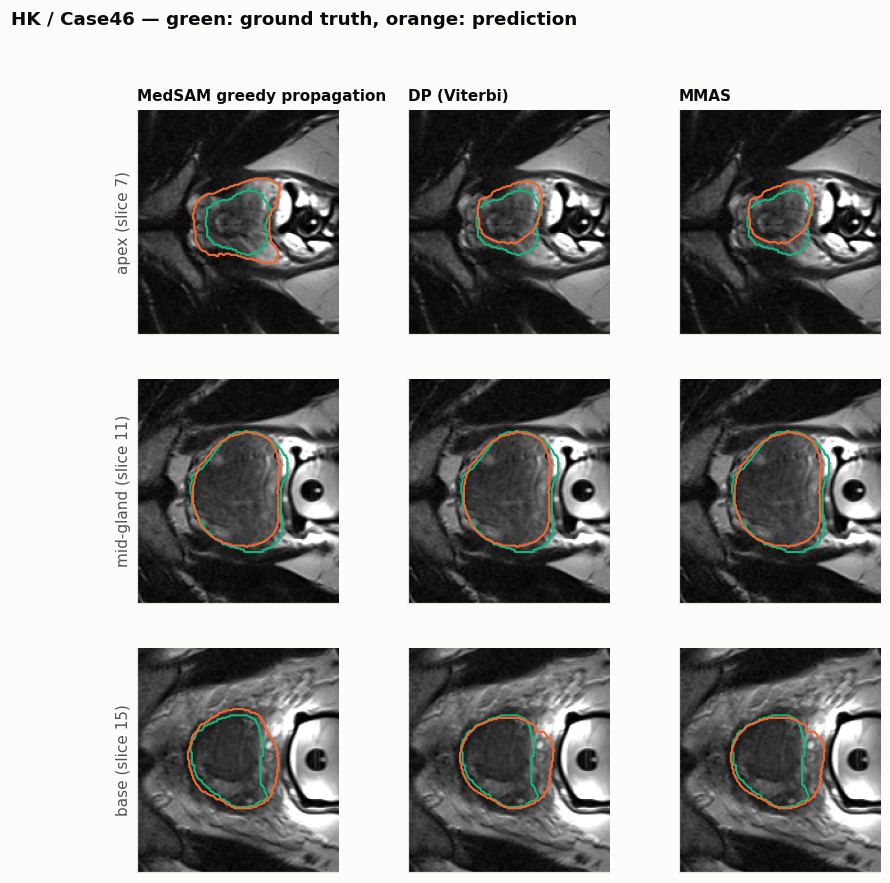

In [31]:
# Fig 4 — qualitative: the test volume where MMAS gains most over greedy propagation
gain = (wide["MMAS"] - wide["MedSAM greedy propagation"]).sort_values(ascending=False)
key = gain.index[0]; v = VOLS[key]
gt_z = np.where(v["gt"].sum((1, 2)) > 0)[0]
zs = [int(gt_z[int(q * (len(gt_z) - 1))]) for q in (0.1, 0.5, 0.9)] if len(gt_z) else [v["gt"].shape[0] // 2] * 3
show = ["MedSAM greedy propagation", "DP (Viterbi)", "MMAS"]
yy, xx = np.where(v["gt"].any(0)); pad = 40
cy = slice(max(yy.min() - pad, 0), yy.max() + pad) if len(yy) else slice(None); cx = slice(max(xx.min() - pad, 0), xx.max() + pad) if len(xx) else slice(None)
fig, axes = plt.subplots(len(zs), len(show), figsize=(3 * len(show), 3 * len(zs)))
for r, z in enumerate(zs):
    for c, m in enumerate(show):
        pm = np.unpackbits(PRED[(key, m)])[: v["gt"].size].reshape(v["gt"].shape).astype(bool)
        ax = axes[r, c]; ax.imshow(v["img255"][z][cy, cx], cmap="gray")
        ax.contour(v["gt"][z][cy, cx], levels=[0.5], colors=["#1baf7a"], linewidths=1.4)
        if pm[z].any(): ax.contour(pm[z][cy, cx], levels=[0.5], colors=[C_ORANGE], linewidths=1.4)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if r == 0: ax.set_title(m, fontsize=10)
        if c == 0: ax.set_ylabel(["apex", "mid-gland", "base"][r] + f" (slice {z})")
fig.suptitle(f"{key[0]} / {key[1]} — green: ground truth, orange: prediction", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig4_qualitative")

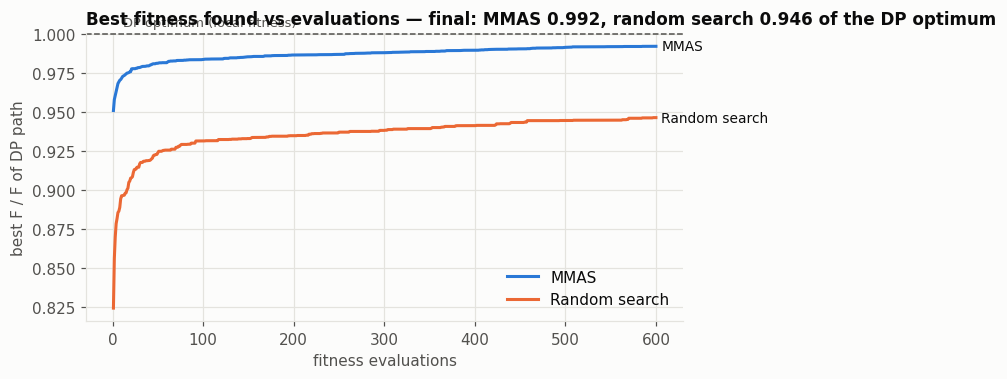

In [32]:
# Fig 5 — search efficiency: best fitness found vs evaluations, relative to the DP optimum (= 1.0)
def mean_curve(curves, n):
    arr = np.full((len(curves), n), np.nan)
    for i, c in enumerate(curves):
        c = c[:n]; arr[i, :len(c)] = c; arr[i, len(c):] = c[-1] if len(c) else np.nan   # early-stopped runs keep their best
    return np.nanmean(arr, 0)
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(1, n_eval + 1); final = {}
for name, color in [("MMAS", C_NIC), ("Random search", C_ORANGE)]:
    if CURVES[name]:
        y = mean_curve(CURVES[name], n_eval); ax.plot(x, y, color=color, lw=2, label=name); final[name] = y[-1]
        ax.text(n_eval * 1.01, y[-1], name, color=INK, va="center", fontsize=9)
ax.axhline(1.0, color=INK2, lw=1, ls="--"); ax.text(n_eval * 0.02, 1.003, "DP optimum (local fitness)", color=INK2, fontsize=8.5, va="bottom")
ax.set_xlabel("fitness evaluations"); ax.set_ylabel("best F / F of DP path"); ax.legend(frameon=False, loc="lower right")
ax.set_title(f"Best fitness found vs evaluations — final: MMAS {final.get('MMAS', np.nan):.3f}, "
             f"random search {final.get('Random search', np.nan):.3f} of the DP optimum")
savefig(fig, "fig5_convergence")

## 9 · Early go/no-go checks (preview of week 8)

These use the ground truth **only for evaluation**, never inside the search. They answer: is there room to win by choosing better boxes, and does the label-free score point in the right direction?

In [33]:
# (a) Headroom and candidate recall
head = per_vol.pivot_table(index=["site", "case"], columns="method", values="dice")
headroom = float((head["Oracle selection"] - head["MedSAM best box"]).mean())
recall = float(gstats.candidate_recall.mean())

# (b) Does MedSAM's confidence track the true slice Dice?
cx_, cy_ = [], []
for key in test_list:
    for nd in VOLS[key]["nodes"]:
        if len(nd["conf"]) > 1 and VOLS[key]["gt"][nd["d"]].any():
            cx_ += list(nd["conf"][1:]); cy_ += list(nd["true_dice"][1:])
rho_conf = stats.spearmanr(cx_, cy_).correlation if len(cx_) > 2 else np.nan

# (c) Does the fitness F track the true 3D Dice? (random paths per volume)
rho_fit = []
for key in test_list:
    v = VOLS[key]
    if v["window"] is None: continue
    rng = np.random.default_rng(0)
    probs = np.isfinite(v["C"]).astype(float); probs /= probs.sum(1, keepdims=True)
    P = (rng.random((N_RANDOM_PATHS_CHECK, v["L"], 1)) < probs.cumsum(1)[None]).argmax(2)
    P = np.vstack([P, dp_viterbi(v)[None], best_box_path(v)[None], oracle_selection_path(v)[None]])
    fv = fitness(v, P); dv = [dice3d(path_to_mask(v, p), v["gt"]) for p in P]
    rho_fit.append(stats.spearmanr(fv, dv).correlation)
rho_fit_med = float(np.nanmedian(rho_fit)) if rho_fit else np.nan

checks = pd.DataFrame([
    dict(check="Headroom: oracle selection − best box (3D Dice)", value=round(headroom, 3), target="≥ ~0.03", passed=headroom >= 0.03),
    dict(check="Candidate recall (slices with a box of Dice ≥ 0.7)", value=round(recall, 3), target="≥ ~0.80", passed=recall >= 0.8),
    dict(check=f"Spearman: MedSAM {CONF_SOURCE} vs true slice Dice", value=round(rho_conf, 3), target="≥ ~0.40", passed=rho_conf >= 0.4),
    dict(check="Median Spearman: fitness F vs true 3D Dice", value=round(rho_fit_med, 3), target="≥ ~0.50", passed=rho_fit_med >= 0.5),
])
checks.to_csv(OUT / "table_go_no_go_preview.csv", index=False)
checks

,check,value,target,passed
0,Headroom: oracle selection − best box (3D Dice),0.056,≥ ~0.03,True
1,Candidate recall (slices with a box of Dice ≥ ...,0.533,≥ ~0.80,False
2,Spearman: MedSAM iou_pred vs true slice Dice,0.326,≥ ~0.40,False
3,Median Spearman: fitness F vs true 3D Dice,0.840,≥ ~0.50,True


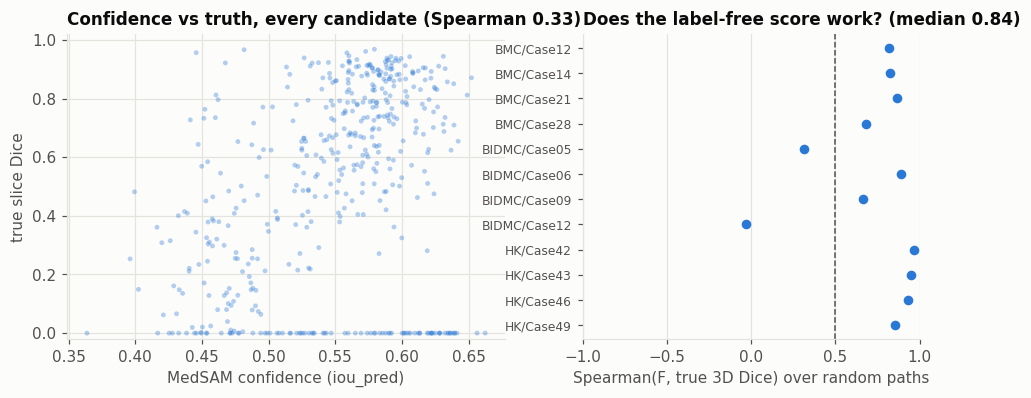

In [34]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw=dict(width_ratios=[1.3, 1]))
a1.scatter(cx_, cy_, s=10, color=C_NIC, alpha=0.35, edgecolor="none")
a1.set_xlabel(f"MedSAM confidence ({CONF_SOURCE})"); a1.set_ylabel("true slice Dice"); a1.set_ylim(-0.02, 1.02)
a1.set_title(f"Confidence vs truth, every candidate (Spearman {rho_conf:.2f})")
labels = [f"{s}/{c}" for (s, c) in test_list if VOLS[(s, c)]["window"] is not None]
a2.scatter(rho_fit, range(len(rho_fit)), color=C_NIC, s=28, zorder=3)
a2.axvline(0.5, color=INK2, lw=1, ls="--"); a2.set_xlim(-1, 1)
a2.set_yticks(range(len(labels))); a2.set_yticklabels(labels, fontsize=8); a2.invert_yaxis(); a2.grid(axis="y", visible=False)
a2.set_xlabel("Spearman(F, true 3D Dice) over random paths")
a2.set_title(f"Does the label-free score work? (median {rho_fit_med:.2f})")
savefig(fig, "fig6_go_no_go_checks")

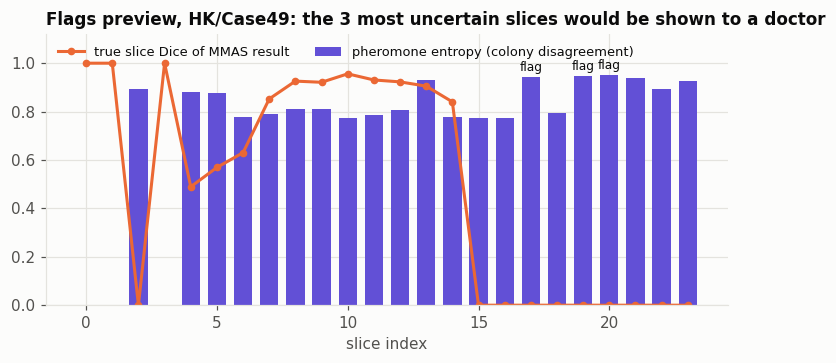

In [35]:
# Fig 7 — pheromone disagreement per slice (preview of the doctor-review flags), on the qualitative volume
if not ENTROPY:
    raise SystemExit("No test volume had a search window, so there is no pheromone map to show.")
key_e = key if key in ENTROPY else next(iter(ENTROPY))
v = VOLS[key_e]; ent = ENTROPY[key_e]
pm = np.unpackbits(PRED[(key_e, "MMAS")])[: v["gt"].size].reshape(v["gt"].shape).astype(bool)
zs_w = [nd["d"] for nd in v["nodes"]]
sd = [slice_dice(pm[z], v["gt"][z].astype(bool)) for z in zs_w]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(zs_w, ent, color=C_NIC2, width=0.7, label="pheromone entropy (colony disagreement)")
ax.plot(zs_w, sd, color=C_ORANGE, lw=2, marker="o", ms=4, label="true slice Dice of MMAS result")
top = np.argsort(ent)[-3:]
for t in top: ax.annotate("flag", (zs_w[t], ent[t]), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8, color=INK)
ax.set_ylim(0, 1.12); ax.set_xlabel("slice index"); ax.legend(frameon=False, loc="upper left", fontsize=8.5, ncol=2)
ax.set_title(f"Flags preview, {key_e[0]}/{key_e[1]}: the 3 most uncertain slices would be shown to a doctor")
savefig(fig, "fig7_flags_preview")

## 10 · Why the colony matters once a global term is added (small demo)

DP is exact only for terms between neighbouring slices. Here the penalty **Pen** (extra disconnected pieces along the slice axis) is switched on. DP cannot represent it, so it keeps its old path; MMAS optimises the full score. Phase 2 adds the real global terms (3D shape autoencoder, volume range).

In [36]:
W_PEN_DEMO = 0.2
demo = []
for key in test_list:
    v = VOLS[key]
    if v["window"] is None: continue
    p_dp = dp_viterbi(v)
    f_dp = float(fitness(v, p_dp, W_PEN_DEMO)[0])
    p_aco, _, _ = mmas(v, np.random.default_rng(0), seed_path=p_dp, w_pen=W_PEN_DEMO)
    demo.append(dict(site=key[0], case=key[1], F_full_DP=f_dp, F_full_MMAS_DPseed=float(fitness(v, p_aco, W_PEN_DEMO)[0]),
                     pieces_DP=pieces_and_jumps(path_to_mask(v, p_dp))[0], pieces_MMAS=pieces_and_jumps(path_to_mask(v, p_aco))[0],
                     dice_DP=dice3d(path_to_mask(v, p_dp), v["gt"]), dice_MMAS=dice3d(path_to_mask(v, p_aco), v["gt"])))
demo = pd.DataFrame(demo); demo.to_csv(OUT / "table_global_term_demo.csv", index=False)
print(f"Volumes where MMAS finds a higher full score than DP: {(demo.F_full_MMAS_DPseed > demo.F_full_DP + 1e-9).sum()} / {len(demo)}")
demo.round(3)

Volumes where MMAS finds a higher full score than DP: 7 / 12


,site,case,F_full_DP,F_full_MMAS_DPseed,pieces_DP,pieces_MMAS,dice_DP,dice_MMAS
0,BMC,Case12,1.066,1.258,2,1,0.668,0.668
1,BMC,Case14,0.498,0.694,5,4,0.642,0.656
2,BMC,Case21,0.774,0.960,3,2,0.540,0.541
3,BMC,Case28,0.780,0.965,3,2,0.588,0.583
4,BIDMC,Case05,0.899,0.899,3,3,0.214,0.214
5,BIDMC,Case06,0.674,1.049,4,2,0.635,0.630
6,BIDMC,Case09,0.830,0.830,3,3,0.553,0.553
7,BIDMC,Case12,1.360,1.360,1,1,0.058,0.058
8,HK,Case42,1.352,1.352,1,1,0.891,0.891
9,HK,Case43,1.058,1.225,2,1,0.782,0.783


## 11 · Summary for the Phase 1 report, and download

In [37]:
mean_d = per_vol.groupby("method").dice.mean()
lines = [
    f"Test set: {len(test_list)} volumes from {', '.join(TEST_SITES)} (unseen hospitals); proposer trained on {SOURCE_SITE} only "
    f"(validation 3D Dice {best_val:.3f}).",
    f"Proposer alone: 3D Dice {mean_d.get('Proposer only', np.nan):.3f}. MedSAM best box per slice: {mean_d.get('MedSAM best box', np.nan):.3f}. "
    f"Greedy propagation: {mean_d.get('MedSAM greedy propagation', np.nan):.3f}.",
    f"DP (Viterbi): {mean_d.get('DP (Viterbi)', np.nan):.3f}. MMAS: {mean_d.get('MMAS', np.nan):.3f}. "
    f"MMAS + DP seed: {mean_d.get('MMAS + DP seed', np.nan):.3f}. Random search (same budget): {mean_d.get('Random search', np.nan):.3f}.",
    f"Upper bounds: oracle selection {mean_d.get('Oracle selection', np.nan):.3f}, oracle boxes {mean_d.get('Oracle boxes', np.nan):.3f}.",
    f"Go/no-go preview: headroom {headroom:.3f}, candidate recall {recall:.2f}, confidence Spearman {rho_conf:.2f}, "
    f"fitness Spearman (median) {rho_fit_med:.2f}.",
    "Local-only fitness: DP is exact, so MMAS is expected to match it; global terms, ACO_R refinement, flags/corrections "
    "and competing colonies follow in Phase 2.",
]
summary_txt = "\n".join("- " + l for l in lines)
(OUT / "summary.md").write_text(summary_txt)
print(summary_txt)
json.dump({k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, list, type(None)))},
          open(OUT / "config_used.json", "w"), indent=1, default=str)
shutil.make_archive(str(WORK / "week7_outputs"), "zip", OUT)
print("\nAll outputs zipped to", WORK / "week7_outputs.zip")
if IN_COLAB:
    from google.colab import files; files.download(str(WORK / "week7_outputs.zip"))

- Test set: 12 volumes from BMC, BIDMC, HK (unseen hospitals); proposer trained on RUNMC only (validation 3D Dice 0.844).
- Proposer alone: 3D Dice 0.599. MedSAM best box per slice: 0.595. Greedy propagation: 0.520.
- DP (Viterbi): 0.603. MMAS: 0.602. MMAS + DP seed: 0.603. Random search (same budget): 0.587.
- Upper bounds: oracle selection 0.650, oracle boxes 0.888.
- Go/no-go preview: headroom 0.056, candidate recall 0.53, confidence Spearman 0.33, fitness Spearman (median) 0.84.
- Local-only fitness: DP is exact, so MMAS is expected to match it; global terms, ACO_R refinement, flags/corrections and competing colonies follow in Phase 2.

All outputs zipped to /kaggle/working/pherosam/week7_outputs.zip
